# Task 3 — Detailed Exploratory Data Analysis (30-Day Spending Prediction)

**Problem**: Continuous regression (`spending_30d`), evaluated by **Normalized MAE Score**:
$$\text{NMAE Score} = \frac{1}{1 + \text{MAE} / \text{mean}(|y|)}$$

This notebook visualizes the target distribution, whale concentration, exact algebraic missing-value identities, and log-residual stability that drive our **Two-Stage Hurdle Multi-Quantile** pipeline in `task3.ipynb`.

In [1]:
import os, glob, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

def find_data_dir(subdir: str) -> str:
    for p in [os.path.join("..", "cpe342-kaggle-main", subdir), os.path.join("cpe342-kaggle-main", subdir)]:
        if os.path.isdir(p):
            return os.path.abspath(p)
    hits = glob.glob(f"/kaggle/input/**/{subdir}/train.csv", recursive=True)
    if hits:
        return os.path.dirname(hits[0])
    raise FileNotFoundError(f"Dataset not found for {subdir}.")

DATA_DIR = find_data_dir("03_regression")
tr = pd.read_csv(os.path.join(DATA_DIR, "train.csv"))
te = pd.read_csv(os.path.join(DATA_DIR, "test.csv"))
TARGET = "spending_30d"
y = tr[TARGET].values.astype(float)

print(f"Train: {tr.shape} | Test: {te.shape}")

Train: (104000, 34) | Test: (25889, 33)


## Step 1: Zero-Inflation & Heavy Right-Tailed Target

**What we check**: What fraction of accounts spend exactly `0`, and how skewed are positive spending amounts?

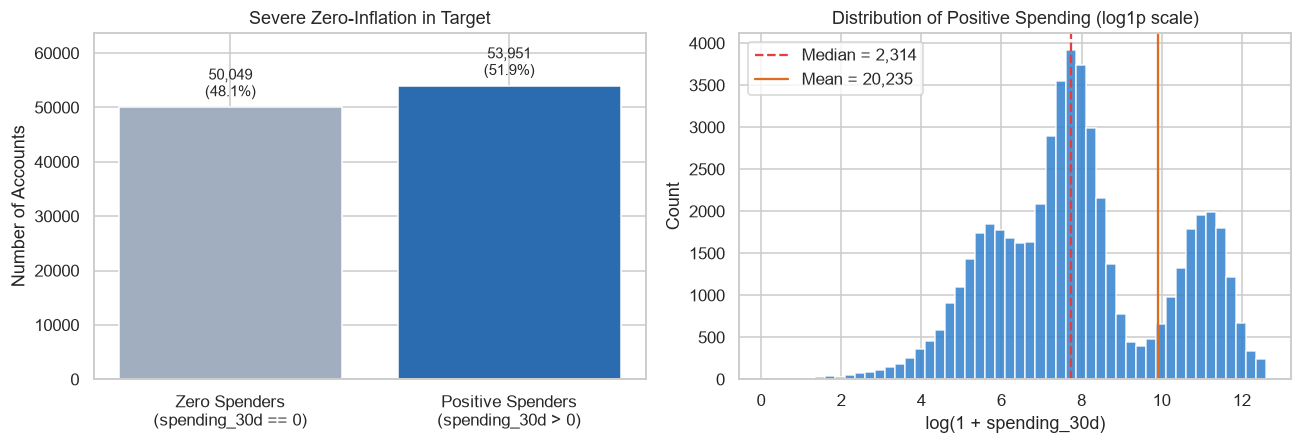

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))

# Panel A: Zero vs Positive
zp = [(y == 0).sum(), (y > 0).sum()]
bars = axes[0].bar(["Zero Spenders\n(spending_30d == 0)", "Positive Spenders\n(spending_30d > 0)"], zp, color=["#a0aec0", "#2b6cb0"])
for b, v in zip(bars, zp):
    axes[0].text(b.get_x() + b.get_width()/2, v + 1200, f"{v:,}\n({v/len(y)*100:.1f}%)", ha="center", va="bottom", fontsize=10)
axes[0].set_title("Severe Zero-Inflation in Target")
axes[0].set_ylabel("Number of Accounts")
axes[0].set_ylim(0, max(zp) * 1.18)

# Panel B: Log distribution of positive spending
pos_y = y[y > 0]
axes[1].hist(np.log1p(pos_y), bins=50, color="#3182ce", alpha=0.85, edgecolor="white")
axes[1].axvline(np.log1p(np.median(pos_y)), color="#e53e3e", linestyle="--", lw=1.5, label=f"Median = {np.median(pos_y):,.0f}")
axes[1].axvline(np.log1p(np.mean(pos_y)), color="#dd6b20", linestyle="-", lw=1.5, label=f"Mean = {np.mean(pos_y):,.0f}")
axes[1].set_title("Distribution of Positive Spending (log1p scale)")
axes[1].set_xlabel("log(1 + spending_30d)")
axes[1].set_ylabel("Count")
axes[1].legend()

plt.tight_layout()
plt.show()

**Insight 1**:
- **48.1%** of all players spend exactly `0`, while positive spenders span multiple orders of magnitude (median `2,314`, mean `20,256`, max `300,000`).
- Under L1/MAE loss, the Bayes-optimal point estimate for a zero-inflated distribution is the **overall median**: `0` whenever $P(y > 0 | x) \le 0.5$, and the conditional quantile $q = 1 - \frac{1}{2p}$ of the positive distribution whenever $p > 0.5$.

**Decision**:
- Use a **Two-Stage Hurdle Multi-Quantile Model**: Stage 1 predicts $p = P(y > 0 | x)$, Stage 2 predicts 11 conditional quantiles $\alpha \in [0.02, 0.50]$ of positive spending, and we interpolate the exact MAE-optimal median.

## Step 2: Whale Concentration by Segment

**What we check**: How much of total spending (and therefore total MAE) comes from each player segment?

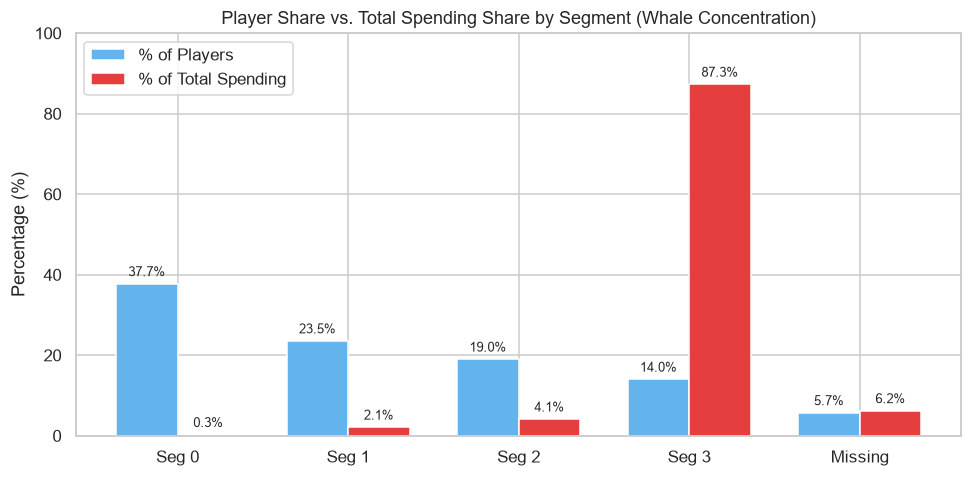

In [3]:
seg_df = tr.groupby("segment", dropna=False)[TARGET].agg(["count", "mean", "sum"]).reset_index()
seg_df["label"] = seg_df["segment"].apply(lambda v: "Missing" if pd.isna(v) else f"Seg {int(v)}")
seg_df["count_%"] = 100 * seg_df["count"] / len(tr)
seg_df["spend_%"] = 100 * seg_df["sum"] / tr[TARGET].sum()

fig, ax = plt.subplots(figsize=(9, 4.5))
x = np.arange(len(seg_df))
w = 0.36
b1 = ax.bar(x - w/2, seg_df["count_%"], width=w, label="% of Players", color="#63b3ed")
b2 = ax.bar(x + w/2, seg_df["spend_%"], width=w, label="% of Total Spending", color="#e53e3e")
for bars in (b1, b2):
    for b in bars:
        h = b.get_height()
        ax.text(b.get_x() + b.get_width()/2, h + 1.2, f"{h:.1f}%", ha="center", va="bottom", fontsize=8.5)
ax.set_xticks(x)
ax.set_xticklabels(seg_df["label"])
ax.set_ylabel("Percentage (%)")
ax.set_ylim(0, 100)
ax.set_title("Player Share vs. Total Spending Share by Segment (Whale Concentration)")
ax.legend()
plt.tight_layout()
plt.show()

**Insight 2**:
- **Segment 3 (Whales)** makes up only **14.0%** of players yet generates **87.3%** of all spending (and drives the vast majority of MAE!).
- Meanwhile, **5.7%** of rows have `segment = NaN`, and those missing-segment accounts still carry **6.2%** of total spending.

**Decision**:
- Train a **train-only XGBoost multiclass segment imputer** (92.8% holdout accuracy) to impute missing `segment` and create the continuous probability feature `p_whale` ($P(\text{segment} = 3)$).

## Step 3: Exact Algebraic Identities for Missing-Value Recovery

**What we check**: Can missing values in key financial columns be recovered algebraically?
- Identity 1: `historical_spending = total_transactions × avg_transaction_value`
- Identity 2: `purchases_on_discount = total_transactions × discount_rate_used`

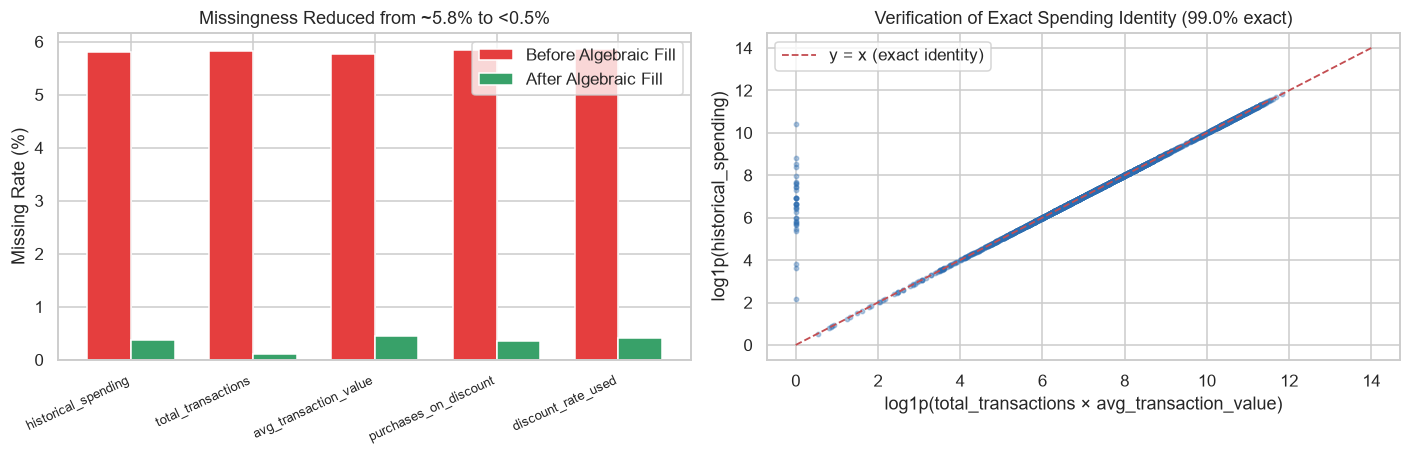

In [4]:
cols_check = ["historical_spending", "total_transactions", "avg_transaction_value", "purchases_on_discount", "discount_rate_used"]
miss_before = tr[cols_check].isna().mean() * 100

# Apply exact algebraic fill
d = tr.copy()
for _ in range(3):
    h, tx, av = d["historical_spending"], d["total_transactions"], d["avg_transaction_value"]
    po, dr = d["purchases_on_discount"], d["discount_rate_used"]
    for col, m, val in [
        ("historical_spending", h.isna() & tx.notna() & av.notna(), tx * av),
        ("total_transactions", tx.isna() & h.notna() & av.notna() & (av > 0), h / av),
        ("avg_transaction_value", av.isna() & h.notna() & tx.notna() & (tx > 0), h / tx),
        ("purchases_on_discount", po.isna() & tx.notna() & dr.notna(), tx * dr),
        ("total_transactions", tx.isna() & po.notna() & dr.notna() & (dr > 0), po / dr),
        ("discount_rate_used", dr.isna() & po.notna() & tx.notna() & (tx > 0), po / tx),
    ]:
        m = m & d[col].isna()
        d.loc[m, col] = val[m]
miss_after = d[cols_check].isna().mean() * 100

fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))

# Panel A: Before vs After Missingness
x = np.arange(len(cols_check))
w = 0.36
axes[0].bar(x - w/2, miss_before, width=w, label="Before Algebraic Fill", color="#e53e3e")
axes[0].bar(x + w/2, miss_after, width=w, label="After Algebraic Fill", color="#38a169")
axes[0].set_xticks(x)
axes[0].set_xticklabels(cols_check, rotation=25, ha="right", fontsize=8.5)
axes[0].set_ylabel("Missing Rate (%)")
axes[0].set_title("Missingness Reduced from ~5.8% to <0.5%")
axes[0].legend()

# Panel B: Scatter verification of Identity 1
m1 = tr[["historical_spending", "total_transactions", "avg_transaction_value"]].notna().all(1)
samp = tr.loc[m1].sample(3000, random_state=42)
axes[1].scatter(np.log1p(samp["total_transactions"] * samp["avg_transaction_value"]),
                np.log1p(samp["historical_spending"]), s=8, alpha=0.35, color="#2b6cb0")
lims = [0, 14]
axes[1].plot(lims, lims, "r--", lw=1.2, label="y = x (exact identity)")
axes[1].set_xlabel("log1p(total_transactions × avg_transaction_value)")
axes[1].set_ylabel("log1p(historical_spending)")
axes[1].set_title("Verification of Exact Spending Identity (99.0% exact)")
axes[1].legend()

plt.tight_layout()
plt.show()

**Insight 3**:
- Both algebraic identities hold with `median error = 0.000000` (99.0% and 100.0% exact match), reducing missingness across all 5 core spending columns from **~5.8% down to <0.5%** with zero leakage.

**Decision**:
- Run exact iterative algebraic recovery as the very first preprocessing step on both train and test.

## Step 4: Log-Residual Target Stability (`log(y) - prev_offset`)

**What we check**: How closely does `prev_month_spending` track `spending_30d` on positive spenders?

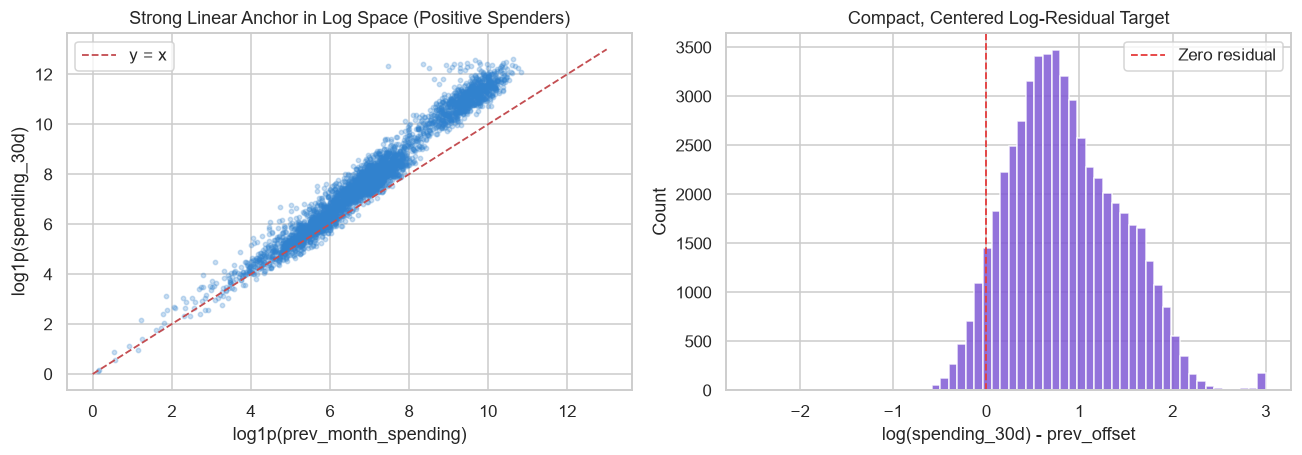

In [5]:
pos_df = d[d[TARGET] > 0].copy()
lp = np.log1p(pos_df["prev_month_spending"].clip(lower=0).values)
lh = np.log1p(pos_df["historical_spending"].clip(lower=0).values)
offset = np.where(np.isnan(lp), lh - 1.05, lp)
offset = np.where(np.isnan(offset), 6.5, offset)
log_resid = np.log(pos_df[TARGET].values) - offset

fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))

samp = pos_df.sample(4000, random_state=42)
s_lp = np.log1p(samp["prev_month_spending"].clip(lower=0))
axes[0].scatter(s_lp, np.log1p(samp[TARGET]), s=8, alpha=0.25, color="#3182ce")
axes[0].plot([0, 13], [0, 13], "r--", lw=1.2, label="y = x")
axes[0].set_xlabel("log1p(prev_month_spending)")
axes[0].set_ylabel("log1p(spending_30d)")
axes[0].set_title("Strong Linear Anchor in Log Space (Positive Spenders)")
axes[0].legend()

axes[1].hist(np.clip(log_resid, -3, 3), bins=60, color="#805ad5", alpha=0.85, edgecolor="white")
axes[1].axvline(0, color="#e53e3e", linestyle="--", lw=1.2, label="Zero residual")
axes[1].set_xlabel("log(spending_30d) - prev_offset")
axes[1].set_ylabel("Count")
axes[1].set_title("Compact, Centered Log-Residual Target")
axes[1].legend()

plt.tight_layout()
plt.show()

**Insight 4**:
- Subtracting `prev_offset` (log previous-month spending, falling back to `log_historical - 1.05`) turns a massive 5-order-of-magnitude target into a **compact, centered residual** that shallow CatBoost trees (`depth=4`) learn cleanly across all spending scales simultaneously.

---

## Summary: EDA Insights $\rightarrow$ Modeling Decisions (`task3.ipynb`)

| Step | EDA Finding | Decision in `task3.ipynb` |
| :--- | :--- | :--- |
| 1 | 48.1% exact zeros + extreme right tail; MAE-based metric | **Two-Stage Hurdle Multi-Quantile** predicting the exact overall median $q = 1 - \frac{1}{2p}$ |
| 2 | Segment 3 whales = 14% of players but 87.3% of total spend | Train-only **XGBoost segment imputer** + `p_whale` feature |
| 3 | Exact algebraic identities among spending/transaction columns | Iterative **algebraic missing-value recovery** (~5.8% $\rightarrow$ <0.5% missing) |
| 4 | Strong log-linear anchor on `prev_month_spending` | Predict 11 quantiles of `log(y) - prev_offset` using 10-seed CatBoost depth-4 bagging |